## Setup

In [2]:
import copy
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import optuna
import optuna
import seaborn as sns
import torch
import torch.nn as nn
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import (
    GroupShuffleSplit,
    StratifiedGroupKFold,
)
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset
from xgboost import XGBClassifier

RANDOM_STATE = 251026

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)


Device: cpu


## General exploration

In [3]:
DATA_PATH = Path("large_object_vgg3d_embeddings_processed.csv")
df = pd.read_csv(DATA_PATH)

print("Data path:", DATA_PATH)
print("Shape:", df.shape)
display(df.head())
display(df.dtypes.value_counts())

Data path: large_object_vgg3d_embeddings_processed.csv
Shape: (381, 130)


,cell_type,sample_group,vgg_emb_000,vgg_emb_001,vgg_emb_002,vgg_emb_003,vgg_emb_004,vgg_emb_005,vgg_emb_006,vgg_emb_007,...,vgg_emb_118,vgg_emb_119,vgg_emb_120,vgg_emb_121,vgg_emb_122,vgg_emb_123,vgg_emb_124,vgg_emb_125,vgg_emb_126,vgg_emb_127
0,m0,sample_group_079,0.039772,0.0,1.179048,0.0,0.0,0.0,1.221995,0.0,...,0.0,0.0,0.0,0.797191,1.709197,0.0,0.777199,0.0,1.924863,0.0
1,m0,sample_group_079,0.000000,0.0,4.433527,0.0,0.0,0.0,5.810353,0.0,...,0.0,0.0,0.0,3.935624,6.289729,0.0,2.987612,0.0,8.424339,0.0
2,m0,sample_group_079,0.000000,0.0,4.108049,0.0,0.0,0.0,5.343654,0.0,...,0.0,0.0,0.0,3.621442,5.779456,0.0,2.740911,0.0,7.669261,0.0
3,m0,sample_group_079,0.000000,0.0,4.042331,0.0,0.0,0.0,5.283560,0.0,...,0.0,0.0,0.0,3.587561,5.783239,0.0,2.660382,0.0,7.480461,0.0
4,m0,sample_group_079,0.000000,0.0,2.474535,0.0,0.0,0.0,3.063431,0.0,...,0.0,0.0,0.0,2.021839,3.586300,0.0,1.637182,0.0,4.486126,0.0


float64    128
object       2
Name: count, dtype: int64

In [4]:
display(pd.Series(df.columns, name="column"))
    
display(df.dtypes.rename("dtype").to_frame())

display(df.isna().sum().sort_values(ascending=False).rename("missing").to_frame())

for column in ["cell_type", "sample_group"]:
    print(f"{column}: {df[column].nunique()} unique values")
    display(df[column].value_counts(dropna=False).rename("count").to_frame())

0         cell_type
1      sample_group
2       vgg_emb_000
3       vgg_emb_001
4       vgg_emb_002
           ...     
125     vgg_emb_123
126     vgg_emb_124
127     vgg_emb_125
128     vgg_emb_126
129     vgg_emb_127
Name: column, Length: 130, dtype: object

,dtype
cell_type,object
sample_group,object
vgg_emb_000,float64
vgg_emb_001,float64
vgg_emb_002,float64
...,...
vgg_emb_123,float64
vgg_emb_124,float64
vgg_emb_125,float64
vgg_emb_126,float64


,missing
cell_type,0
vgg_emb_095,0
vgg_emb_093,0
vgg_emb_092,0
vgg_emb_091,0
...,...
vgg_emb_036,0
vgg_emb_035,0
vgg_emb_034,0
vgg_emb_033,0


cell_type: 3 unique values


,count
cell_type,
m2,145
m0,132
m1,104


sample_group: 85 unique values


,count
sample_group,
sample_group_053,22
sample_group_021,22
sample_group_049,14
sample_group_079,13
sample_group_081,13
...,...
sample_group_070,1
sample_group_067,1
sample_group_083,1


Above we can see class counts for each cell type (and also sample_group)

In [5]:
df.info(verbose=True, show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 381 entries, 0 to 380
Data columns (total 130 columns):
 #    Column        Non-Null Count  Dtype  
---   ------        --------------  -----  
 0    cell_type     381 non-null    object 
 1    sample_group  381 non-null    object 
 2    vgg_emb_000   381 non-null    float64
 3    vgg_emb_001   381 non-null    float64
 4    vgg_emb_002   381 non-null    float64
 5    vgg_emb_003   381 non-null    float64
 6    vgg_emb_004   381 non-null    float64
 7    vgg_emb_005   381 non-null    float64
 8    vgg_emb_006   381 non-null    float64
 9    vgg_emb_007   381 non-null    float64
 10   vgg_emb_008   381 non-null    float64
 11   vgg_emb_009   381 non-null    float64
 12   vgg_emb_010   381 non-null    float64
 13   vgg_emb_011   381 non-null    float64
 14   vgg_emb_012   381 non-null    float64
 15   vgg_emb_013   381 non-null    float64
 16   vgg_emb_014   381 non-null    float64
 17   vgg_emb_015   381 non-null    float64
 18   vgg_emb_

From this info we see that all features are non-null, therefore no missingness in this dataset

In [6]:
display(df.describe().T)


display(df.isna().sum().sort_values(ascending=False).head(15).rename("missing").to_frame())


,count,mean,std,min,25%,50%,75%,max
vgg_emb_000,381.0,0.009492,0.034612,0.000000,0.000000,0.000000,0.000000,0.183263
vgg_emb_001,381.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
vgg_emb_002,381.0,4.253172,2.794121,0.000000,2.205972,3.645934,5.784087,17.109690
vgg_emb_003,381.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
vgg_emb_004,381.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...
vgg_emb_123,381.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
vgg_emb_124,381.0,2.833346,1.868895,0.094944,1.453587,2.417135,3.866113,11.759638
vgg_emb_125,381.0,0.000031,0.000310,0.000000,0.000000,0.000000,0.000000,0.003633
vgg_emb_126,381.0,8.065610,5.587925,0.136789,3.953052,6.817931,11.175075,34.557022


,missing
cell_type,0
vgg_emb_095,0
vgg_emb_093,0
vgg_emb_092,0
vgg_emb_091,0
vgg_emb_090,0
vgg_emb_089,0
vgg_emb_088,0
vgg_emb_087,0
vgg_emb_086,0


Again, we see that there are no missing values, and also some info about embedings distribution.

In [7]:

constant_features = [column for column in df.columns if df[column].nunique(dropna=False) <= 1]
constant_features


['vgg_emb_001',
 'vgg_emb_003',
 'vgg_emb_004',
 'vgg_emb_007',
 'vgg_emb_014',
 'vgg_emb_015',
 'vgg_emb_017',
 'vgg_emb_018',
 'vgg_emb_019',
 'vgg_emb_027',
 'vgg_emb_034',
 'vgg_emb_036',
 'vgg_emb_039',
 'vgg_emb_044',
 'vgg_emb_048',
 'vgg_emb_049',
 'vgg_emb_057',
 'vgg_emb_059',
 'vgg_emb_060',
 'vgg_emb_069',
 'vgg_emb_072',
 'vgg_emb_074',
 'vgg_emb_076',
 'vgg_emb_078',
 'vgg_emb_079',
 'vgg_emb_086',
 'vgg_emb_087',
 'vgg_emb_096',
 'vgg_emb_098',
 'vgg_emb_099',
 'vgg_emb_100',
 'vgg_emb_103',
 'vgg_emb_115',
 'vgg_emb_118',
 'vgg_emb_119',
 'vgg_emb_120',
 'vgg_emb_123']

We can't use constant features for moddeling (they give us nothing), so filtering df without them.

In [8]:
df_filtered = df.copy()
df_filtered = df_filtered[[column for column in df.columns if column not in constant_features]]

In [9]:
df_filtered.shape

(381, 93)

In [10]:
display(df_filtered.describe().T)

,count,mean,std,min,25%,50%,75%,max
vgg_emb_000,381.0,0.009492,0.034612,0.000000,0.000000,0.000000,0.000000,0.183263
vgg_emb_002,381.0,4.253172,2.794121,0.000000,2.205972,3.645934,5.784087,17.109690
vgg_emb_005,381.0,0.003010,0.025074,0.000000,0.000000,0.000000,0.000000,0.242966
vgg_emb_006,381.0,5.553719,3.925257,0.000000,2.631457,4.681877,7.632102,23.262154
vgg_emb_008,381.0,5.465348,3.816128,0.000000,2.650400,4.650739,7.560846,22.967373
...,...,...,...,...,...,...,...,...
vgg_emb_122,381.0,6.041894,3.945404,0.141752,3.101588,5.168819,8.163948,23.272848
vgg_emb_124,381.0,2.833346,1.868895,0.094944,1.453587,2.417135,3.866113,11.759638
vgg_emb_125,381.0,0.000031,0.000310,0.000000,0.000000,0.000000,0.000000,0.003633
vgg_emb_126,381.0,8.065610,5.587925,0.136789,3.953052,6.817931,11.175075,34.557022


## EDA

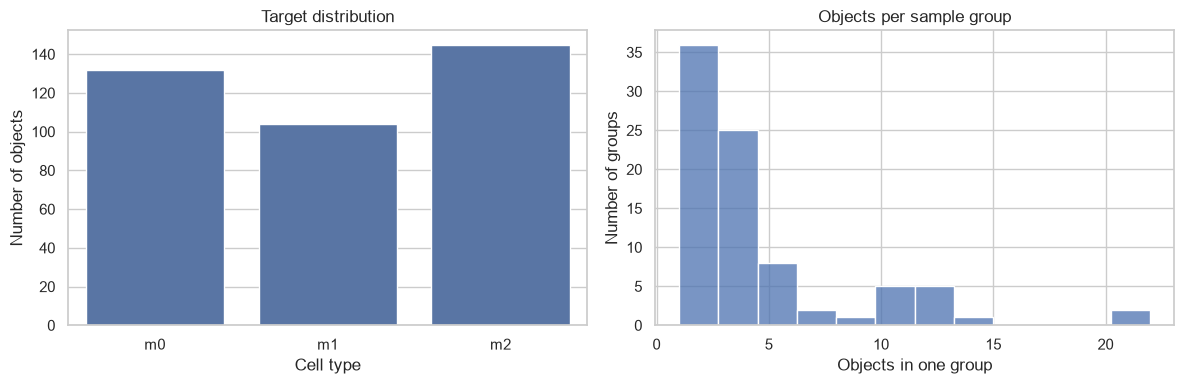

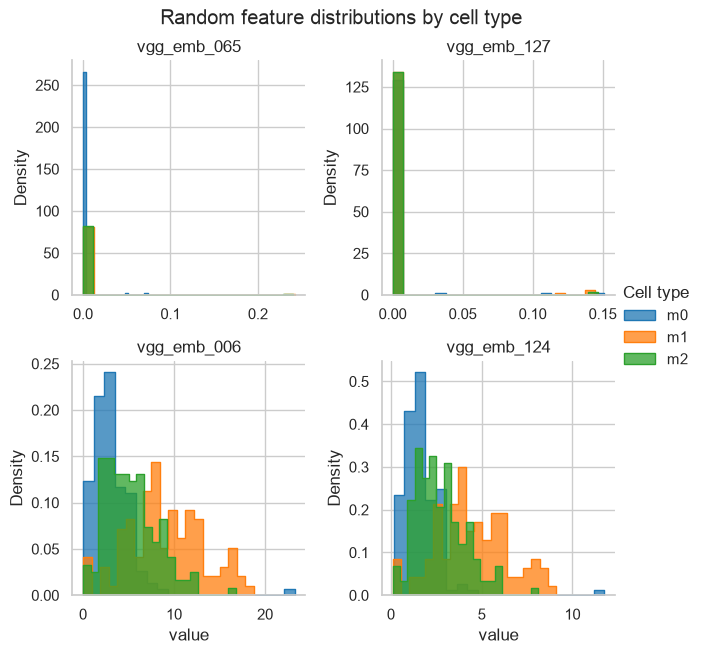

In [11]:
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
random.seed(RANDOM_STATE)
plot_features = random.sample(list(df_filtered.columns), k=4, )

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(
    data=df_filtered,
    x="cell_type",
    order=["m0", "m1", "m2"],
    ax=axes[0],
)
axes[0].set_title("Target distribution")
axes[0].set_xlabel("Cell type")
axes[0].set_ylabel("Number of objects")

group_sizes = df_filtered["sample_group"].value_counts()
sns.histplot(group_sizes, bins=12, ax=axes[1])
axes[1].set_title("Objects per sample group")
axes[1].set_xlabel("Objects in one group")
axes[1].set_ylabel("Number of groups")

plt.tight_layout()
plt.show()

if plot_features:
    long_features = df_filtered.melt(
        id_vars=["cell_type"],
        value_vars=plot_features,
        var_name="feature",
        value_name="value",
    )
    
    g = sns.FacetGrid(
        long_features,
        col="feature",
        col_wrap=2,
        hue="cell_type",   
        sharex=False,
        sharey=False,
        height=3.2,
        palette="tab10"   
    )
    
    g.map_dataframe(
        sns.histplot,
        x="value",          
        bins=20,
        element="step",
        stat="density",
        common_norm=False,
    )
    
    g.add_legend(title="Cell type")
    g.set_titles("{col_name}")
    g.fig.suptitle("Random feature distributions by cell type", y=1.02)
    plt.show()

,feature,eta_squared,mutual_information
0,vgg_emb_085,0.346077,0.322386
1,vgg_emb_045,0.448413,0.319669
2,vgg_emb_025,0.374302,0.313292
3,vgg_emb_107,0.341223,0.310920
4,vgg_emb_089,0.356949,0.304872
5,vgg_emb_117,0.368442,0.304095
6,vgg_emb_110,0.363816,0.301943
7,vgg_emb_106,0.379010,0.300855
8,vgg_emb_088,0.354250,0.300259
9,vgg_emb_109,0.369916,0.300108


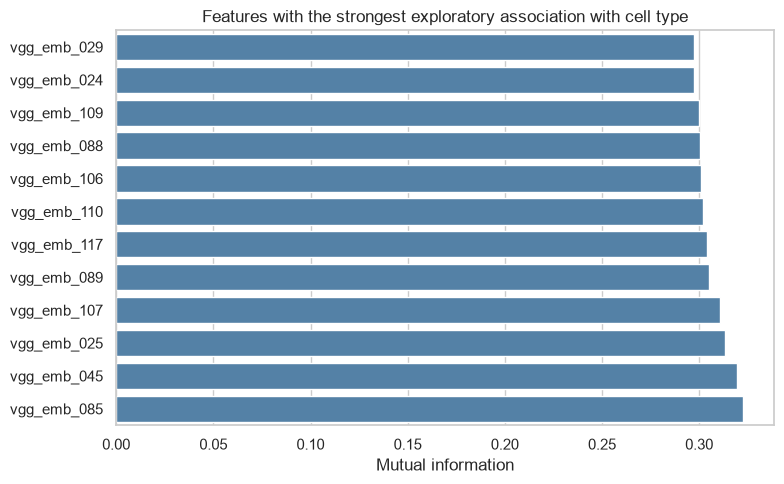

In [12]:
from sklearn.feature_selection import mutual_info_classif

association_rows = []
target_codes = df_filtered["cell_type"].map({"m0": 0, "m1": 1, "m2": 2})
candidate_features = df_filtered.select_dtypes(include=np.number).columns.tolist()
for feature in candidate_features:
    values = df_filtered[feature]
    feature_values = values.to_numpy()
    feature_target = target_codes.to_numpy()

    if len(feature_values) < 3 or np.isclose(np.var(feature_values), 0):
        eta_squared = np.nan
        mutual_information = 0.0
    else:
        grand_mean = feature_values.mean()
        grouped = pd.DataFrame({
            "value": feature_values,
            "target": feature_target,
        }).groupby("target")["value"]
        group_means = grouped.mean()
        group_counts = grouped.size()
        ss_between = ((group_means - grand_mean) ** 2 * group_counts).sum()
        ss_total = ((feature_values - grand_mean) ** 2).sum()
        eta_squared = ss_between / ss_total if ss_total > 0 else np.nan

        mutual_information = mutual_info_classif(
            pd.DataFrame({feature: feature_values}),
            feature_target,
            random_state=RANDOM_STATE,
        )[0]

    association_rows.append({
        "feature": feature,
        "eta_squared": eta_squared,
        "mutual_information": mutual_information,
    })

association = (
    pd.DataFrame(association_rows)
    .sort_values("mutual_information", ascending=False)
    .reset_index(drop=True)
)

display(association.head(15))

top_association = association.head(12).sort_values("mutual_information")
plt.figure(figsize=(8, 5))
sns.barplot(
    data=top_association,
    x="mutual_information",
    y="feature",
    color="steelblue",
)
plt.title("Features with the strongest exploratory association with cell type")
plt.xlabel("Mutual information")
plt.ylabel("")
plt.tight_layout()
plt.show()

As we have a lot of features, it makes sense to remove highly correlated ones (leaving only one from pair, with bigger mutual information)

In [13]:
threshold = 0.95
mi_series = association.copy()
mi_series = mi_series.set_index(mi_series["feature"])
mi_series = mi_series['mutual_information']
sorted_features = mi_series.loc[candidate_features].sort_values(ascending=False).index.tolist()

corr_matrix = df_filtered[sorted_features].corr(method='pearson').abs()

final_features = []
dropped_features = set()

for feature in sorted_features:
    if feature not in dropped_features:
        final_features.append(feature)
    
        highly_correlated = corr_matrix.index[corr_matrix[feature] > threshold].tolist()
        for corr_feat in highly_correlated:
            if corr_feat != feature:
                dropped_features.add(corr_feat)

print(f"Original candidate features: {len(sorted_features)}")
print(f"Selected features to keep: {len(final_features)}")
print(f"Dropped features: {len(dropped_features)}")


Original candidate features: 91
Selected features to keep: 17
Dropped features: 74


In [14]:
df_final = df_filtered[final_features+['sample_group', 'cell_type']]
df_final.shape

(381, 19)

## Splits and scaling

In [15]:
TARGET = "cell_type"
GROUP_COLUMN = "sample_group"
META_COLUMNS = [TARGET, GROUP_COLUMN]

feature_cols = [column for column in df_final.columns if column not in META_COLUMNS]
X = df_final[feature_cols].copy()
y = df_final[TARGET].copy()
groups = df_final[GROUP_COLUMN].copy()

print("Number of features:", len(feature_cols))
print("Feature matrix shape:", X.shape)
print("Target values:", sorted(y.unique()))
print("Number of sample groups:", groups.nunique())

Number of features: 17
Feature matrix shape: (381, 17)
Target values: ['m0', 'm1', 'm2']
Number of sample groups: 85


Stratified group-aware train-test split

In [16]:
def split_quality(test_indices, y_values, target_fraction):
    overall_proportions = y_values.value_counts(normalize=True).sort_index()
    test_proportions = (
        y_values.iloc[test_indices]
        .value_counts(normalize=True)
        .reindex(overall_proportions.index)
        .fillna(0)
    )
    size_error = abs(len(test_indices) / len(y_values) - target_fraction)
    class_error = np.abs(test_proportions - overall_proportions).sum()
    return size_error + class_error


outer_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)
outer_splits = list(outer_splitter.split(X, y, groups=groups))

outer_fold_index = min(
    range(len(outer_splits)),
    key=lambda index: split_quality(
        outer_splits[index][1],
        y,
        target_fraction=0.20,
    ),
)
train_idx, test_idx = outer_splits[outer_fold_index]

X_train_full = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()
y_train_full = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()
groups_train_full = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

shared_groups = set(groups_train_full).intersection(groups_test)

print("Selected outer fold:", outer_fold_index)
print("Training objects:", len(X_train_full))
print("Test objects:", len(X_test))
print("Training groups:", groups_train_full.nunique())
print("Test groups:", groups_test.nunique())
print("Shared groups:", len(shared_groups))
print("Overall class proportions:")
print(y.value_counts(normalize=True).sort_index())
print("Test class proportions:")
print(y_test.value_counts(normalize=True).sort_index())

assert len(shared_groups) == 0
assert set(y_test.unique()) == set(y.unique())

Selected outer fold: 0
Training objects: 305
Test objects: 76
Training groups: 69
Test groups: 16
Shared groups: 0
Overall class proportions:
cell_type
m0    0.346457
m1    0.272966
m2    0.380577
Name: proportion, dtype: float64
Test class proportions:
cell_type
m0    0.342105
m1    0.276316
m2    0.381579
Name: proportion, dtype: float64


Stratified group-aware validation split

In [17]:
inner_splitter = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=RANDOM_STATE + 1,
)
inner_splits = list(
    inner_splitter.split(
        X_train_full,
        y_train_full,
        groups=groups_train_full,
    )
)

inner_fold_index = min(
    range(len(inner_splits)),
    key=lambda index: split_quality(
        inner_splits[index][1],
        y_train_full,
        target_fraction=0.25,
    ),
)
train_idx2, val_idx = inner_splits[inner_fold_index]

X_train = X_train_full.iloc[train_idx2].copy()
X_val = X_train_full.iloc[val_idx].copy()
y_train = y_train_full.iloc[train_idx2].copy()
y_val = y_train_full.iloc[val_idx].copy()
groups_train = groups_train_full.iloc[train_idx2].copy()
groups_val = groups_train_full.iloc[val_idx].copy()

shared_train_val_groups = set(groups_train).intersection(groups_val)

print("Selected inner fold:", inner_fold_index)
print("Training objects:", len(X_train))
print("Validation objects:", len(X_val))
print("Training groups:", groups_train.nunique())
print("Validation groups:", groups_val.nunique())
print("Shared train/validation groups:", len(shared_train_val_groups))
print("Training class proportions:")
print(y_train.value_counts(normalize=True).sort_index())
print("Validation class proportions:")
print(y_val.value_counts(normalize=True).sort_index())

assert len(shared_train_val_groups) == 0
assert set(y_val.unique()) == set(y.unique())

Selected inner fold: 0
Training objects: 228
Validation objects: 77
Training groups: 52
Validation groups: 17
Shared train/validation groups: 0
Training class proportions:
cell_type
m0    0.350877
m1    0.271930
m2    0.377193
Name: proportion, dtype: float64
Validation class proportions:
cell_type
m0    0.337662
m1    0.272727
m2    0.389610
Name: proportion, dtype: float64


Now scaling (no imputation because no missingness).

In [18]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Missing values before imputation:")
print("train:", int(X_train.isna().sum().sum()))
print("validation:", int(X_val.isna().sum().sum()))
print("test:", int(X_test.isna().sum().sum()))

print("Scaled shapes:")
print("train:", X_train_scaled.shape)
print("validation:", X_val_scaled.shape)
print("test:", X_test_scaled.shape)
print("Missing values after imputation:", int(np.isnan(X_train_scaled).sum()))
print("First five training means:", X_train_scaled.mean(axis=0)[:5])
print("First five training standard deviations:", X_train_scaled.std(axis=0)[:5])

Missing values before imputation:
train: 0
validation: 0
test: 0
Scaled shapes:
train: (228, 17)
validation: (77, 17)
test: (76, 17)
Missing values after imputation: 0
First five training means: [ 3.89551938e-17 -6.23283102e-17 -1.67507334e-16 -1.05179023e-16
  5.45372714e-17]
First five training standard deviations: [1. 1. 1. 1. 1.]


## Exploratory t-SNE and UMAP

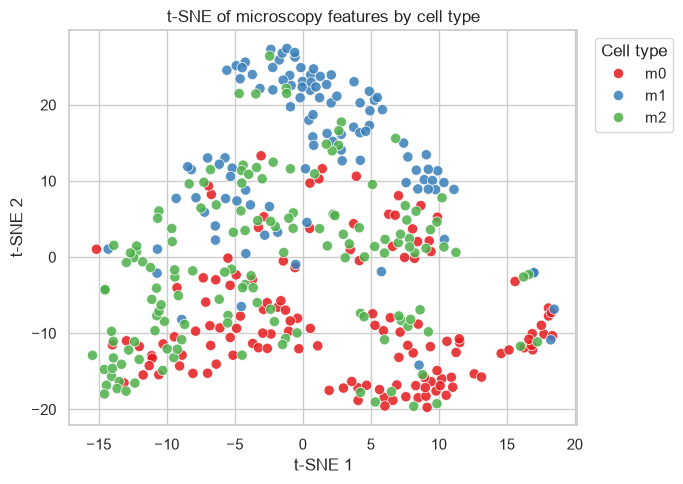

In [19]:

X_all_scaled = scaler.transform(X)

tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=RANDOM_STATE,
)
X_tsne = tsne.fit_transform(X_all_scaled)

tsne_plot = pd.DataFrame({
    "TSNE1": X_tsne[:, 0],
    "TSNE2": X_tsne[:, 1],
    "cell_type": y.to_numpy(),
})

plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=tsne_plot,
    x="TSNE1",
    y="TSNE2",
    hue="cell_type",
    hue_order=["m0", "m1", "m2"],
    palette="Set1",
    s=55,
    alpha=0.85,
)
plt.title("t-SNE of microscopy features by cell type")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.legend(title="Cell type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

The cell types seem to be overlapping but still with some separation (left part seems to be more occupied by green, top by blue, right by red)

/Users/sasha/Desktop/KSE/ml/KSE_ML_for_bioinformatics/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


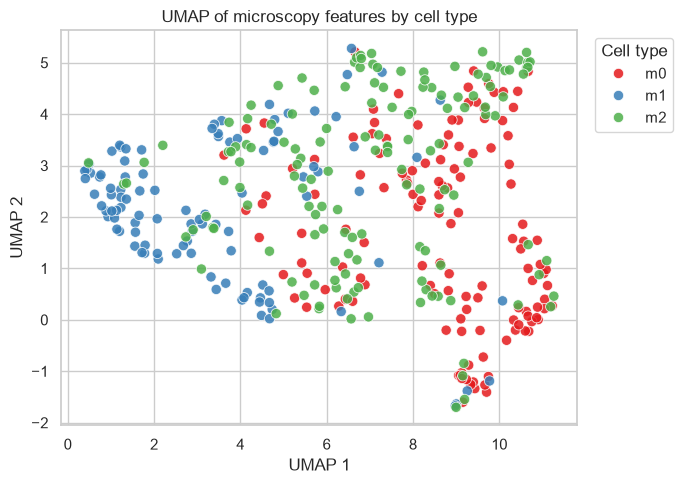

In [20]:
import umap

X_all_scaled = scaler.transform(X)

reducer = umap.UMAP(
    n_components=2,
    n_neighbors=30, 
    min_dist=0.25,
    random_state=RANDOM_STATE,
)
X_umap = reducer.fit_transform(X_all_scaled)

umap_plot = pd.DataFrame({
    "UMAP1": X_umap[:, 0],
    "UMAP2": X_umap[:, 1],
    "cell_type": y.to_numpy(),
})

plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=umap_plot,
    x="UMAP1",
    y="UMAP2",
    hue="cell_type",
    hue_order=["m0", "m1", "m2"],
    palette="Set1",
    s=55,
    alpha=0.85,
)
plt.title("UMAP of microscopy features by cell type")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.legend(title="Cell type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

Similarly to t-SNE looks like classes overlap while still having some "dominatinf" areas

## Baseline and MLP models

In [21]:
log_reg = LogisticRegression(
    solver='lbfgs',
    max_iter=2000,
    random_state=RANDOM_STATE, 
    n_jobs=1
)

log_reg.fit(X_train_scaled, y_train)

pred_val = log_reg.predict(X_val_scaled)

print("Validation Set Results:")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_val, pred_val):.3f}")
print(f"Macro F1 Score:    {f1_score(y_val, pred_val, average='macro'):.3f}")
print("\nClassification Report (Validation):")
print(classification_report(y_val, pred_val))

pred_test = log_reg.predict(X_test_scaled)

print("\nTest Set Results")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, pred_test):.3f}")
print(f"Macro F1 Score:    {f1_score(y_test, pred_test, average='macro'):.3f}")
print("\nClassification Report (Test):")
print(classification_report(y_test, pred_test))

Validation Set Results:
Balanced Accuracy: 0.636
Macro F1 Score:    0.626

Classification Report (Validation):
              precision    recall  f1-score   support

          m0       0.53      0.38      0.44        26
          m1       0.78      0.86      0.82        21
          m2       0.57      0.67      0.62        30

    accuracy                           0.62        77
   macro avg       0.63      0.64      0.63        77
weighted avg       0.61      0.62      0.61        77


Test Set Results
Balanced Accuracy: 0.738
Macro F1 Score:    0.717

Classification Report (Test):
              precision    recall  f1-score   support

          m0       0.80      0.92      0.86        26
          m1       0.65      0.81      0.72        21
          m2       0.70      0.48      0.57        29

    accuracy                           0.72        76
   macro avg       0.72      0.74      0.72        76
weighted avg       0.72      0.72      0.71        76



/Users/sasha/Desktop/KSE/ml/KSE_ML_for_bioinformatics/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


The above is logistic regression baseline, the next step is simple MLP.

In [22]:
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_t = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)

class_names = sorted(y.unique())
class_to_index = {name: index for index, name in enumerate(class_names)}

y_train_t = torch.tensor(
    y_train.map(class_to_index).to_numpy(),
    dtype=torch.long,
)
y_val_t = torch.tensor(
    y_val.map(class_to_index).to_numpy(),
    dtype=torch.long,
)
y_test_t = torch.tensor(
    y_test.map(class_to_index).to_numpy(),
    dtype=torch.long,
)

print("Class mapping:", class_to_index)
print("Training tensor shapes:", X_train_t.shape, y_train_t.shape)
print("Validation tensor shapes:", X_val_t.shape, y_val_t.shape)
print("Test tensor shapes:", X_test_t.shape, y_test_t.shape)

Class mapping: {'m0': 0, 'm1': 1, 'm2': 2}
Training tensor shapes: torch.Size([228, 17]) torch.Size([228])
Validation tensor shapes: torch.Size([77, 17]) torch.Size([77])
Test tensor shapes: torch.Size([76, 17]) torch.Size([76])


In [23]:
y_test_t

tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2])

In [24]:
from torch.utils.data import TensorDataset, DataLoader

BATCH_SIZE = 32

train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset = TensorDataset(X_val_t, y_val_t)
test_dataset = TensorDataset(X_test_t, y_test_t)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 8
Validation batches: 3
Test batches: 3


In [25]:
class MLP(nn.Module):
    def __init__(self, input_dim, n_classes):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, n_classes)
        )

    def forward(self, x):
        return self.network(x)


In [26]:
input_dim = X_train_scaled.shape[1]
n_classes = len(class_names)

model = MLP(
    input_dim=input_dim,
    n_classes=n_classes,
).to(DEVICE)

print(model)

MLP(
  (network): Sequential(
    (0): Linear(in_features=17, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=3, bias=True)
  )
)


In [27]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3)

print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [28]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        logits = model(X_batch)

        loss = criterion(logits, y_batch)

        loss.backward()

        optimizer.step()

        total_loss += loss.item() * X_batch.size(0)

        pred = logits.argmax(dim=1)

        total_correct += (pred == y_batch).sum().item()
        total_samples += X_batch.size(0)

    return (
        total_loss / total_samples,
        total_correct / total_samples
    )


In [29]:
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        logits = model(X_batch)

        loss = criterion(logits, y_batch)

        total_loss += loss.item() * X_batch.size(0)

        pred = logits.argmax(dim=1)

        total_correct += (pred == y_batch).sum().item()
        total_samples += X_batch.size(0)

    return (
        total_loss / total_samples,
        total_correct / total_samples
    )


In [30]:
N_EPOCHS = 50
criterion = nn.CrossEntropyLoss()

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

for epoch in range(N_EPOCHS):
     train_loss, train_acc = train_one_epoch(
         model,
         train_loader,
         criterion,
         optimizer,
         DEVICE)

     val_loss, val_acc = evaluate(
         model,
         val_loader,
         criterion,
         DEVICE)

     history["train_loss"].append(train_loss)
     history["val_loss"].append(val_loss)
     history["train_acc"].append(train_acc)
     history["val_acc"].append(val_acc)

     if (epoch + 1) % 5 == 0:
         print(
             f"Epoch {epoch+1:03d} | "
             f"train loss={train_loss:.4f} | "
             f"val loss={val_loss:.4f} | "
             f"train acc={train_acc:.3f} | "
             f"val acc={val_acc:.3f}")


Epoch 005 | train loss=1.0291 | val loss=1.0215 | train acc=0.601 | val acc=0.610
Epoch 010 | train loss=0.9178 | val loss=0.9295 | train acc=0.592 | val acc=0.623
Epoch 015 | train loss=0.7952 | val loss=0.8699 | train acc=0.654 | val acc=0.584
Epoch 020 | train loss=0.7457 | val loss=0.8560 | train acc=0.671 | val acc=0.636
Epoch 025 | train loss=0.7216 | val loss=0.8444 | train acc=0.658 | val acc=0.623
Epoch 030 | train loss=0.7059 | val loss=0.8350 | train acc=0.671 | val acc=0.623
Epoch 035 | train loss=0.6989 | val loss=0.8455 | train acc=0.662 | val acc=0.610
Epoch 040 | train loss=0.6950 | val loss=0.8170 | train acc=0.649 | val acc=0.675
Epoch 045 | train loss=0.6816 | val loss=0.8522 | train acc=0.684 | val acc=0.610
Epoch 050 | train loss=0.6743 | val loss=0.8676 | train acc=0.684 | val acc=0.597


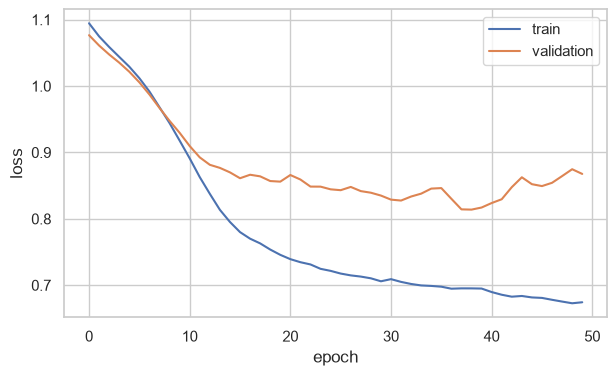

In [31]:
plt.figure(figsize=(7, 4))
plt.plot(history["train_loss"], label="train")
plt.plot(history["val_loss"], label="validation")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()

## Add MLFlow (local)

🏃 View run pytorch-baseline at: http://127.0.0.1:5000/#/experiments/1/runs/538911e5c20d42db8e2de2a6c6db11c6
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


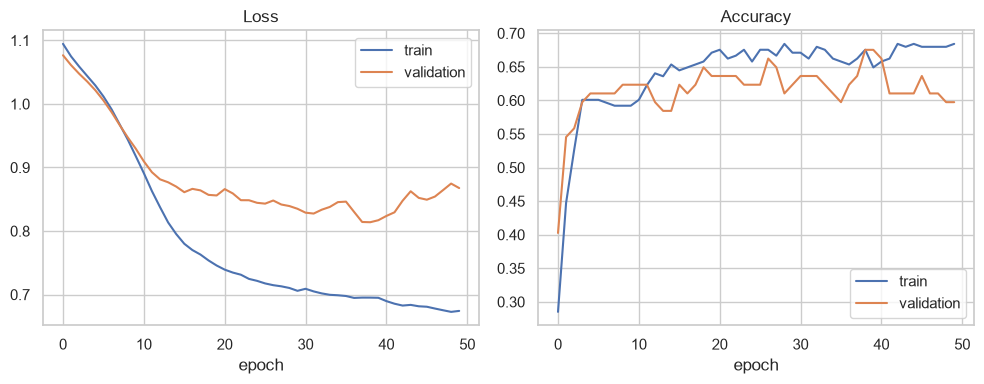

MLflow tracking URI: http://127.0.0.1:5000
MLflow baseline run ID: 538911e5c20d42db8e2de2a6c6db11c6


In [32]:
import os
import tempfile
from pathlib import Path

import sys
import importlib

# Positron can expose its own typing_extensions before the project environment.
# MLflow/FastAPI needs the newer sentinel symbol, so prioritize this project's
# site-packages before importing MLflow.
project_roots = [Path.cwd(), *Path.cwd().parents]
project_root = next(
    (root for root in project_roots if (root / ".venv" / "lib" / "python3.11" / "site-packages").exists()),
    None,
)
if project_root is None:
    raise RuntimeError(
        "Could not locate the practicals .venv. Select the project kernel or run the notebook from the project directory."
    )

project_site_packages = str(project_root / ".venv" / "lib" / "python3.11" / "site-packages")
if project_site_packages not in sys.path:
    sys.path.insert(0, project_site_packages)

loaded_typing_extensions = sys.modules.get("typing_extensions")
if loaded_typing_extensions is not None and not hasattr(loaded_typing_extensions, "sentinel"):
    del sys.modules["typing_extensions"]
    importlib.invalidate_caches()

import typing_extensions
if not hasattr(typing_extensions, "sentinel"):
    raise RuntimeError(
        f"The active kernel is using an incompatible typing_extensions package: {typing_extensions.__file__}"
    )

import mlflow

tracking_uri = os.environ.get("MLFLOW_TRACKING_URI", "http://127.0.0.1:5000")
mlflow.set_tracking_uri(tracking_uri)
mlflow.set_experiment("week6-microscopy-mlp")


def make_training_figure(series):
    figure, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].plot(series["train_loss"], label="train")
    axes[0].plot(series["validation_loss"], label="validation")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("epoch")
    axes[0].legend()
    axes[1].plot(series["train_accuracy"], label="train")
    axes[1].plot(series["validation_accuracy"], label="validation")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("epoch")
    axes[1].legend()
    figure.tight_layout()
    return figure


def log_mlflow_training_run(
    run_name,
    params,
    series=None,
    final_metrics=None,
    model=None,
    model_type=None,
    figure=None,
):
    """Log one comparable experiment to the local MLflow server."""
    params = dict(params)
    if model_type is not None:
        params["model_type"] = model_type

    with mlflow.start_run(run_name=run_name) as active_run:
        mlflow.log_params(params)

        if series:
            for metric_name, values in series.items():
                for epoch, value in enumerate(values, start=1):
                    mlflow.log_metric(metric_name, float(value), step=epoch)

        if final_metrics:
            mlflow.log_metrics({
                name: float(value)
                for name, value in final_metrics.items()
            })

        if figure is not None:
            mlflow.log_figure(figure, "training_curves.png")

        if model is not None:
            with tempfile.TemporaryDirectory() as temporary_directory:
                temporary_directory = Path(temporary_directory)
                if model_type == "pytorch":
                    artifact_file = temporary_directory / "pytorch_state_dict.pt"
                    torch.save(
                        copy.deepcopy(model).to("cpu").state_dict(),
                        artifact_file,
                    )
                elif model_type == "keras":
                    artifact_file = temporary_directory / "keras_model.keras"
                    model.save(artifact_file)
                elif model_type == "xgboost":
                    artifact_file = temporary_directory / "xgboost_model.json"
                    model.save_model(str(artifact_file))
                else:
                    raise ValueError(f"Unsupported model_type: {model_type}")
                mlflow.log_artifact(str(artifact_file), artifact_path="model")

        return active_run.info.run_id


baseline_series = {
    "train_loss": history["train_loss"],
    "validation_loss": history["val_loss"],
    "train_accuracy": history["train_acc"],
    "validation_accuracy": history["val_acc"],
}
baseline_figure = make_training_figure(baseline_series)
baseline_run_id = log_mlflow_training_run(
    run_name="pytorch-baseline",
    params={
        "framework": "pytorch",
        "input_dim": input_dim,
        "hidden_layers": "32,16",
        "n_classes": n_classes,
        "optimizer": "Adam",
        "learning_rate": 1e-3,
        "epochs": len(history["train_loss"]),
        "batch_size": BATCH_SIZE,
        "random_state": RANDOM_STATE,
    },
    series=baseline_series,
    final_metrics={
        "final_validation_loss": history["val_loss"][-1],
        "final_validation_accuracy": history["val_acc"][-1],
        "best_validation_accuracy": max(history["val_acc"]),
    },
    model=model,
    model_type="pytorch",
    figure=baseline_figure,
)
plt.show()
plt.close(baseline_figure)
print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("MLflow baseline run ID:", baseline_run_id)


It looks like at the end (after around epoch 37) the model starts to overfit (validation loss growing while train still drops).

So far MLP is not performing better.

## Experiments

At least 3 learning rates comparison (chose 5: 1e-5, 1e-4, 1e-3, 1e-2, 1e-1):

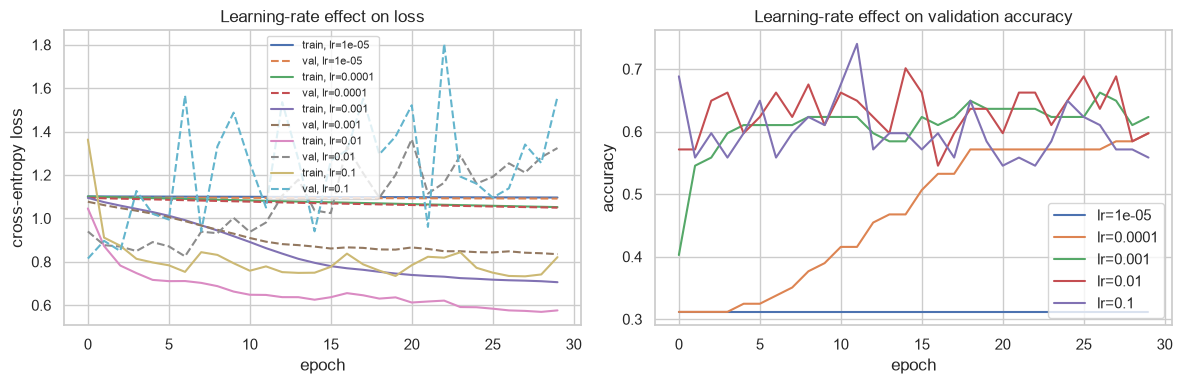

🏃 View run mlp-learning-rate-1e-05 at: http://127.0.0.1:5000/#/experiments/1/runs/016ceb9ebbc24bf9aa6e6423da62dfa2
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run mlp-learning-rate-0.0001 at: http://127.0.0.1:5000/#/experiments/1/runs/169c78033a264484ac2dfbe54276fdcf
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run mlp-learning-rate-0.001 at: http://127.0.0.1:5000/#/experiments/1/runs/bc5392ee8eb749f5bdb0b91404a5cdd0
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run mlp-learning-rate-0.01 at: http://127.0.0.1:5000/#/experiments/1/runs/f7914c658a3a4a61ad7d01b0ed53c187
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run mlp-learning-rate-0.1 at: http://127.0.0.1:5000/#/experiments/1/runs/a3ba4d458fe94d42be846dbc50230289
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


In [33]:
class FlexibleMLP(nn.Module):
    def __init__(self, input_dim, n_classes, hidden_dims=(32, 16), dropout=0.0):
        super().__init__()

        layers = []
        current_dim = input_dim

        for hidden_dim in hidden_dims:
            layers.append(nn.Linear(current_dim, hidden_dim))
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            current_dim = hidden_dim

        layers.append(nn.Linear(current_dim, n_classes))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


def fit_experiment(
    hidden_dims=(32, 16),
    lr=1e-3,
    weight_decay=0.0,
    dropout=0.0,
    epochs=30,
    patience=None,
):
    torch.manual_seed(RANDOM_STATE)

    experiment_model = FlexibleMLP(
        input_dim=input_dim,
        n_classes=n_classes,
        hidden_dims=hidden_dims,
        dropout=dropout,
    ).to(DEVICE)

    experiment_optimizer = torch.optim.Adam(
        experiment_model.parameters(),
        lr=lr,
        weight_decay=weight_decay,
    )

    experiment_history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
    }

    best_state = None
    best_val_loss = np.inf
    best_epoch = epochs
    epochs_without_improvement = 0

    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(
            experiment_model,
            train_loader,
            criterion,
            experiment_optimizer,
            DEVICE,
        )
        val_loss, val_acc = evaluate(
            experiment_model,
            val_loader,
            criterion,
            DEVICE,
        )

        experiment_history["train_loss"].append(train_loss)
        experiment_history["val_loss"].append(val_loss)
        experiment_history["train_acc"].append(train_acc)
        experiment_history["val_acc"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(experiment_model.state_dict())
            best_epoch = epoch + 1
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if patience is not None and epochs_without_improvement >= patience:
            break

    if best_state is not None:
        experiment_model.load_state_dict(best_state)

    return experiment_model, experiment_history, best_epoch


learning_rates = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
learning_rate_results = {}
learning_rate_models = {}

for learning_rate in learning_rates:
    learning_rate_model, history_lr, best_epoch_lr = fit_experiment(
        lr=learning_rate,
        epochs=30,
    )
    learning_rate_models[learning_rate] = learning_rate_model
    learning_rate_results[learning_rate] = {
        "history": history_lr,
        "best_epoch": best_epoch_lr,
    }

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for learning_rate, result in learning_rate_results.items():
    history_lr = result["history"]
    axes[0].plot(history_lr["train_loss"], label=f"train, lr={learning_rate:g}")
    axes[0].plot(history_lr["val_loss"], linestyle="--", label=f"val, lr={learning_rate:g}")
    axes[1].plot(history_lr["val_acc"], label=f"lr={learning_rate:g}")

axes[0].set_title("Learning-rate effect on loss")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("cross-entropy loss")
axes[0].legend(fontsize=8)

axes[1].set_title("Learning-rate effect on validation accuracy")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

for learning_rate, result in learning_rate_results.items():
    history_lr = result["history"]
    lr_series = {
        "train_loss": history_lr["train_loss"],
        "validation_loss": history_lr["val_loss"],
        "train_accuracy": history_lr["train_acc"],
        "validation_accuracy": history_lr["val_acc"],
    }
    log_mlflow_training_run(
        run_name=f"mlp-learning-rate-{learning_rate:g}",
        params={
            "framework": "pytorch",
            "architecture": "32,16",
            "learning_rate": learning_rate,
            "requested_epochs": 30,
            "actual_epochs": len(history_lr["train_loss"]),
            "best_epoch": result["best_epoch"],
            "batch_size": BATCH_SIZE,
            "random_state": RANDOM_STATE,
        },
        series=lr_series,
        final_metrics={
            "best_validation_accuracy": max(history_lr["val_acc"]),
            "best_validation_loss": min(history_lr["val_loss"]),
        },
        model=learning_rate_models[learning_rate],
        model_type="pytorch",
    )


The smoothest curves (both train and val) seem to be for learning rate 1e-3. For bigger learning rates, we can see that validation loss grows and is unstable (seems to overfit again).

Comparing different models, different capcities

,architecture,hidden_dims,parameters,best_epoch,best_validation_accuracy,final_validation_accuracy
3,deep,"(64, 32, 16)",3811,16,0.675325,0.636364
1,medium,"(32, 16)",1155,32,0.662338,0.610390
2,wide,"(128,)",2691,20,0.649351,0.649351
0,small,"(8,)",171,35,0.532468,0.532468


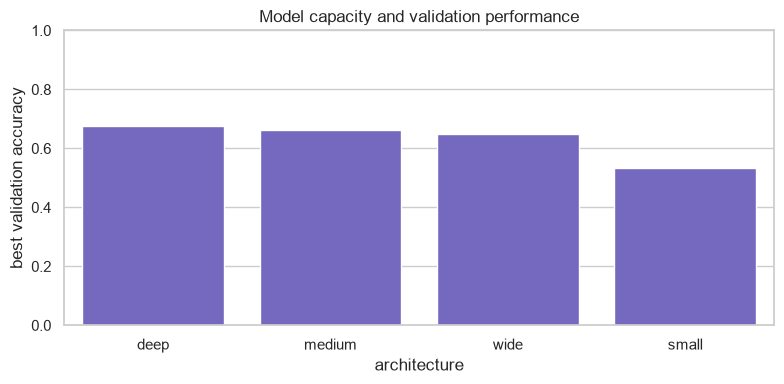

🏃 View run mlp-architecture-small at: http://127.0.0.1:5000/#/experiments/1/runs/f7f83fa6be47464f86c123d75c04907a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run mlp-architecture-medium at: http://127.0.0.1:5000/#/experiments/1/runs/95498958c9a54d5d9e427af2b82b19aa
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run mlp-architecture-wide at: http://127.0.0.1:5000/#/experiments/1/runs/b0cc0cc3ec2a429dac35e3e13b759f5f
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run mlp-architecture-deep at: http://127.0.0.1:5000/#/experiments/1/runs/fddfdf8c086044c29cc99b3686f1fa37
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


In [34]:
architectures = {
    "small": (8,),
    "medium": (32, 16),
    "wide": (128,),
    "deep": (64, 32, 16),
}

def count_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

capacity_results = []
capacity_histories = {}
capacity_models = {}

for name, hidden_dims in architectures.items():
    capacity_model, capacity_history, best_epoch_capacity = fit_experiment(
        hidden_dims=hidden_dims,
        lr=1e-3,
        epochs=35,
    )
    capacity_histories[name] = capacity_history
    capacity_models[name] = capacity_model
    capacity_results.append({
        "architecture": name,
        "hidden_dims": hidden_dims,
        "parameters": count_parameters(capacity_model),
        "best_epoch": best_epoch_capacity,
        "best_validation_accuracy": max(capacity_history["val_acc"]),
        "final_validation_accuracy": capacity_history["val_acc"][-1],
    })

capacity_table = pd.DataFrame(capacity_results).sort_values(
    "best_validation_accuracy",
    ascending=False,
)
display(capacity_table)

plt.figure(figsize=(8, 4))
sns.barplot(
    data=capacity_table,
    x="architecture",
    y="best_validation_accuracy",
    color="slateblue",
)
plt.ylim(0, 1)
plt.ylabel("best validation accuracy")
plt.title("Model capacity and validation performance")
plt.tight_layout()
plt.show()

for name, hidden_dims in architectures.items():
    architecture_history = capacity_histories[name]
    architecture_series = {
        "train_loss": architecture_history["train_loss"],
        "validation_loss": architecture_history["val_loss"],
        "train_accuracy": architecture_history["train_acc"],
        "validation_accuracy": architecture_history["val_acc"],
    }
    log_mlflow_training_run(
        run_name=f"mlp-architecture-{name}",
        params={
            "framework": "pytorch",
            "architecture": name,
            "hidden_dims": str(hidden_dims),
            "requested_epochs": 35,
            "actual_epochs": len(architecture_history["train_loss"]),
            "best_epoch": next(
                row["best_epoch"]
                for row in capacity_results
                if row["architecture"] == name
            ),
            "learning_rate": 1e-3,
            "random_state": RANDOM_STATE,
        },
        series=architecture_series,
        final_metrics={
            "best_validation_accuracy": max(architecture_history["val_acc"]),
            "best_validation_loss": min(architecture_history["val_loss"]),
        },
        model=capacity_models[name],
        model_type="pytorch",
    )


Deep model performs the best. However from MLFlow we can see that it starts to overfit (val loss growing while train still reducing) after step 16.

Now weight decay.

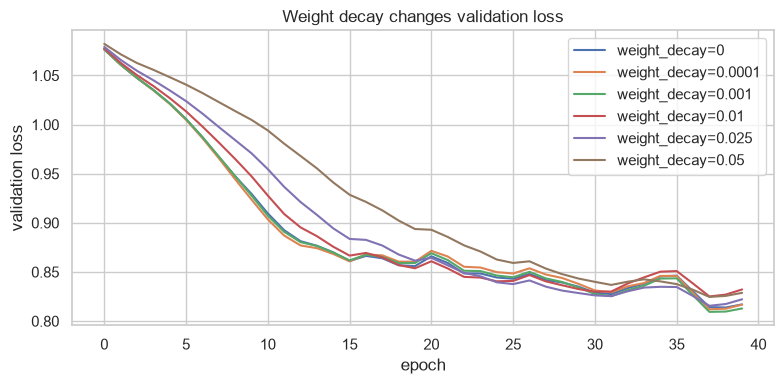

In [35]:
weight_decay_values = [0.0, 1e-4, 1e-3, 0.01, 0.025, 0.05]
weight_decay_results = {}

for weight_decay in weight_decay_values:
    _, history_wd, best_epoch_wd = fit_experiment(
        weight_decay=weight_decay,
        lr=1e-3,
        epochs=40,
    )
    weight_decay_results[weight_decay] = {
        "history": history_wd,
        "best_epoch": best_epoch_wd,
    }

plt.figure(figsize=(8, 4))
for weight_decay, result in weight_decay_results.items():
    plt.plot(
        result["history"]["val_loss"],
        label=f"weight_decay={weight_decay:g}",
    )

plt.xlabel("epoch")
plt.ylabel("validation loss")
plt.title("Weight decay changes validation loss")
plt.legend()
plt.tight_layout()
plt.show()

In this case weight decay doesn't seem to change many things.

Next dropout experiment

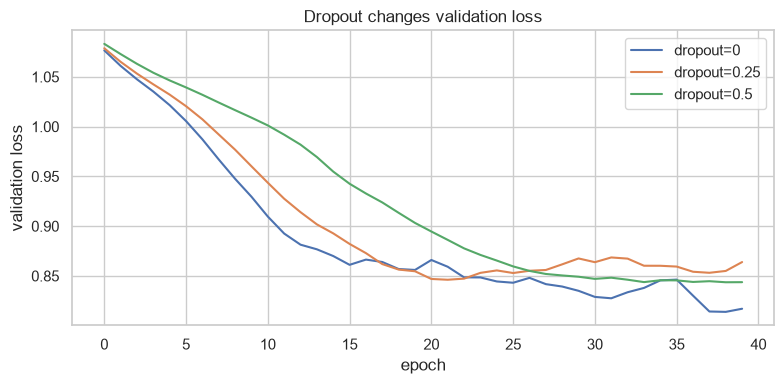

In [36]:
dropout_values = [0.0, 0.25, 0.5]
dropout_results = {}

for dropout_rate in dropout_values:
    _, history_dropout, best_epoch_dropout = fit_experiment(
        dropout=dropout_rate,
        lr=1e-3,
        epochs=40,
    )
    dropout_results[dropout_rate] = {
        "history": history_dropout,
        "best_epoch": best_epoch_dropout,
    }

plt.figure(figsize=(8, 4))
for dropout_rate, result in dropout_results.items():
    plt.plot(
        result["history"]["val_loss"],
        label=f"dropout={dropout_rate:g}",
    )

plt.xlabel("epoch")
plt.ylabel("validation loss")
plt.title("Dropout changes validation loss")
plt.legend()
plt.tight_layout()
plt.show()

Dropout 0 loss is the best, but 0.5 is the smoothest, likely 40 epochs is too few in this case to see positive effect.

Early stopping (with best architecture discovered previously and best lr):

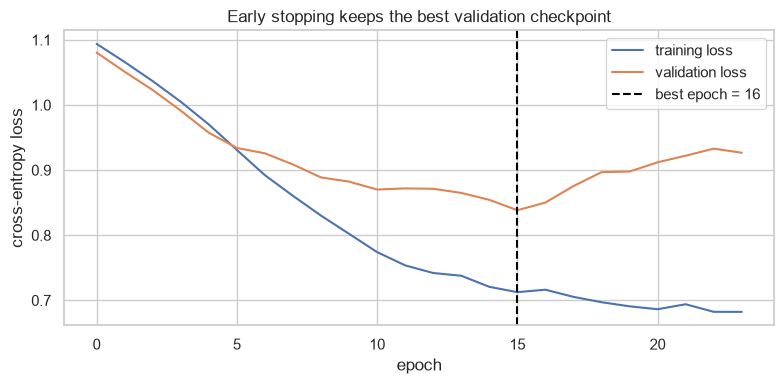

Epochs actually trained: 24
Best validation epoch: 16
🏃 View run mlp-early-stopping at: http://127.0.0.1:5000/#/experiments/1/runs/00c2e1616a894ec49d8bdb083a92a717
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


'00c2e1616a894ec49d8bdb083a92a717'

In [37]:
early_stop_model, early_stop_history, early_stop_best_epoch = fit_experiment(
    hidden_dims=(64, 32, 16),
    lr=1e-3,
    epochs=100,
    patience=8,
)

plt.figure(figsize=(8, 4))
plt.plot(early_stop_history["train_loss"], label="training loss")
plt.plot(early_stop_history["val_loss"], label="validation loss")
plt.axvline(
    early_stop_best_epoch - 1,
    color="black",
    linestyle="--",
    label=f"best epoch = {early_stop_best_epoch}",
)
plt.xlabel("epoch")
plt.ylabel("cross-entropy loss")
plt.title("Early stopping keeps the best validation checkpoint")
plt.legend()
plt.tight_layout()
plt.show()

print("Epochs actually trained:", len(early_stop_history["train_loss"]))
print("Best validation epoch:", early_stop_best_epoch)

log_mlflow_training_run(
    run_name="mlp-early-stopping",
    params={
        "framework": "pytorch",
        "architecture": "64, 32, 16",
        "requested_epochs": 100,
        "actual_epochs": len(early_stop_history["train_loss"]),
        "best_epoch": early_stop_best_epoch,
        "patience": 15,
        "learning_rate": 1e-3,
        "random_state": RANDOM_STATE,
    },
    series={
        "train_loss": early_stop_history["train_loss"],
        "validation_loss": early_stop_history["val_loss"],
        "train_accuracy": early_stop_history["train_acc"],
        "validation_accuracy": early_stop_history["val_acc"],
    },
    final_metrics={
        "best_validation_accuracy": max(early_stop_history["val_acc"]),
        "best_validation_loss": min(early_stop_history["val_loss"]),
    },
    model=early_stop_model,
    model_type="pytorch",
)


In [43]:
early_stop_model.eval()
all_logits = []
all_targets = []

with torch.no_grad():
    for X_batch, y_batch in val_loader:
        all_logits.append(early_stop_model(X_batch.to(DEVICE)).cpu())
        all_targets.append(y_batch.cpu())

val_logits = torch.cat(all_logits).numpy()
y_true = torch.cat(all_targets).numpy()
y_pred = val_logits.argmax(axis=1)
print("Best model MLP val balanced accuracy:", balanced_accuracy_score(y_true, y_pred))
print("Best model MLP val macro F1:", f1_score(y_true, y_pred, average="macro"))


Best model MLP val balanced accuracy: 0.6344322344322344
Best model MLP val macro F1: 0.6161662525126225


By comparing smoothness of loss curves, and validation accuracy, I chose as final version deep model, 1e-3 learning rate, no dropout, stopping on epoch 16.

[I 2026-10-25 22:15:54,742] A new study created in memory with name: no-name-1e41928f-d4f7-4ff3-8c6d-72de17ceb024


  0%|          | 0/20 [00:00<?, ?it/s]

[I 2026-10-25 22:15:54,884] Trial 0 finished with value: 0.581800315132679 and parameters: {'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.029681678681387148, 'min_child_weight': 7, 'subsample': 0.8999999999999999, 'colsample_bytree': 0.7, 'gamma': 0.45935736703248925, 'reg_lambda': 0.06688069314620944}. Best is trial 0 with value: 0.581800315132679.
[I 2026-10-25 22:15:54,930] Trial 1 finished with value: 0.5957891960863871 and parameters: {'n_estimators': 50, 'max_depth': 3, 'learning_rate': 0.12446826320415434, 'min_child_weight': 3, 'subsample': 0.7999999999999999, 'colsample_bytree': 0.7999999999999999, 'gamma': 0.3494361594157957, 'reg_lambda': 0.035512857802380435}. Best is trial 1 with value: 0.5957891960863871.
[I 2026-10-25 22:15:55,003] Trial 2 finished with value: 0.5982986423820842 and parameters: {'n_estimators': 100, 'max_depth': 2, 'learning_rate': 0.019512149889924238, 'min_child_weight': 4, 'subsample': 0.7999999999999999, 'colsample_bytree': 1.0, 'gamma': 0.

,number,value
16,16,0.621455
13,13,0.615946
12,12,0.615608
14,14,0.614142
4,4,0.609808
11,11,0.606068
17,17,0.605761
19,19,0.601512
2,2,0.598299
9,9,0.597792


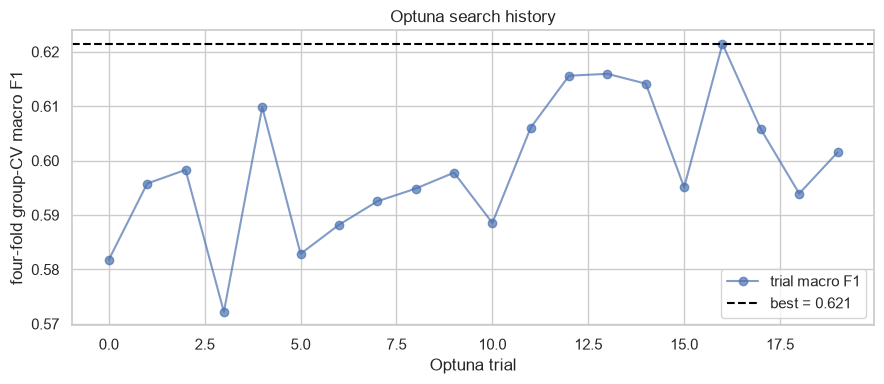

Selected XGBoost validation balanced accuracy: 0.6652014652014652
Selected XGBoost validation macro F1: 0.6526918911364986
Selected XGBoost test balanced accuracy: 0.684202770409667
Selected XGBoost test macro F1: 0.6871212121212121
🏃 View run xgboost-optuna-best at: http://127.0.0.1:5000/#/experiments/1/runs/a56e1dab776b4562b0684ae57b8c95a1
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


'a56e1dab776b4562b0684ae57b8c95a1'

In [38]:
# 1. Prevent macOS OpenMP kernel crashes
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'


xgb_train_y = y_train.map(class_to_index).to_numpy(dtype=np.int64)
xgb_val_y = y_val.map(class_to_index).to_numpy(dtype=np.int64)

xgb_cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE + 2,
)
xgb_cv_splits = list(
    xgb_cv.split(
        X_train,
        xgb_train_y,
        groups=groups_train.to_numpy(),
    )
)

optuna.logging.set_verbosity(optuna.logging.INFO)

def xgb_objective(trial):
    trial_params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 250, step=50),
        "max_depth": trial.suggest_int("max_depth", 2, 6),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.20, log=True),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "subsample": trial.suggest_float("subsample", 0.7, 1.0, step=0.1),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.7, 1.0, step=0.1),
        "gamma": trial.suggest_float("gamma", 0.0, 0.5),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
    }

    fold_scores = []
    for fold_train_idx, fold_val_idx in xgb_cv_splits:
        fold_model = XGBClassifier(
            objective="multi:softprob",
            num_class=n_classes,
            eval_metric="mlogloss",
            tree_method="exact",
            random_state=RANDOM_STATE,
            n_jobs=1,
            verbosity=0,
            **trial_params,
        )
        fold_model.fit(
            X_train.iloc[fold_train_idx],
            xgb_train_y[fold_train_idx],
            eval_set=[(X_train.iloc[fold_train_idx], xgb_train_y[fold_train_idx])],
            verbose=0
        )
        fold_pred = fold_model.predict(X_train.iloc[fold_val_idx]).astype(int)
        fold_scores.append(
            f1_score(
                xgb_train_y[fold_val_idx],
                fold_pred,
                average="macro",
            )
        )

    return float(np.mean(fold_scores))


xgb_study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
)
xgb_study.optimize(
    xgb_objective,
    n_trials=20,
    show_progress_bar=True,
)

print("Completed Optuna trials:", len(xgb_study.trials))
print("Best XGBoost parameters:", xgb_study.best_params)
print(f"Best group-CV macro F1: {xgb_study.best_value:.3f}")

optuna_results = (
    xgb_study.trials_dataframe()
    .query("state == 'COMPLETE'")
    .sort_values("value", ascending=False)
    [["number", "value"]]
    .head(10)
)
display(optuna_results)

all_trial_values = [
    trial.value
    for trial in xgb_study.trials
    if trial.value is not None
]
plt.figure(figsize=(9, 4))
plt.plot(all_trial_values, marker="o", alpha=0.7, label="trial macro F1")
plt.axhline(
    xgb_study.best_value,
    color="black",
    linestyle="--",
    label=f"best = {xgb_study.best_value:.3f}",
)
plt.xlabel("Optuna trial")
plt.ylabel("four-fold group-CV macro F1")
plt.title("Optuna search history")
plt.legend()
plt.tight_layout()
plt.show()

xgb_model = XGBClassifier(
    objective="multi:softprob",
    num_class=n_classes,
    eval_metric="mlogloss",
    tree_method="exact",
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbosity=0,
    **xgb_study.best_params,
)
xgb_model.fit(X_train, xgb_train_y)

pred_xgb_val_codes = xgb_model.predict(X_val).astype(int)
pred_xgb_val = np.asarray(class_names)[pred_xgb_val_codes]

print(
    "Selected XGBoost validation balanced accuracy:",
    balanced_accuracy_score(y_val, pred_xgb_val),
)
print(
    "Selected XGBoost validation macro F1:",
    f1_score(y_val, pred_xgb_val, average="macro"),
)

pred_xgb_codes = xgb_model.predict(X_test).astype(int)
pred_xgb = np.asarray(class_names)[pred_xgb_codes]

print("Selected XGBoost test balanced accuracy:", balanced_accuracy_score(y_test, pred_xgb))
print("Selected XGBoost test macro F1:", f1_score(y_test, pred_xgb, average="macro"))

xgb_validation_metrics = {
    "validation_balanced_accuracy": balanced_accuracy_score(y_val, pred_xgb_val),
    "validation_macro_f1": f1_score(y_val, pred_xgb_val, average="macro"),
    "test_balanced_accuracy": balanced_accuracy_score(y_test, pred_xgb),
    "test_macro_f1": f1_score(y_test, pred_xgb, average="macro"),
    "best_group_cv_macro_f1": xgb_study.best_value,
}
log_mlflow_training_run(
    run_name="xgboost-optuna-best",
    params={
        "framework": "xgboost",
        "search_method": "Optuna TPE",
        "search_trials": len(xgb_study.trials),
        "random_state": RANDOM_STATE,
        **xgb_study.best_params,
    },
    final_metrics=xgb_validation_metrics,
    model=xgb_model,
    model_type="xgboost",
)


Looking at the validation, the XGboost architecture is achieving best balanced accuracy. Therefore it is selected as the final model for evaluation

## Evaluation

              precision    recall  f1-score   support

          m0      0.864     0.731     0.792        26
          m1      0.609     0.667     0.636        21
          m2      0.613     0.655     0.633        29

    accuracy                          0.684        76
   macro avg      0.695     0.684     0.687        76
weighted avg      0.698     0.684     0.688        76



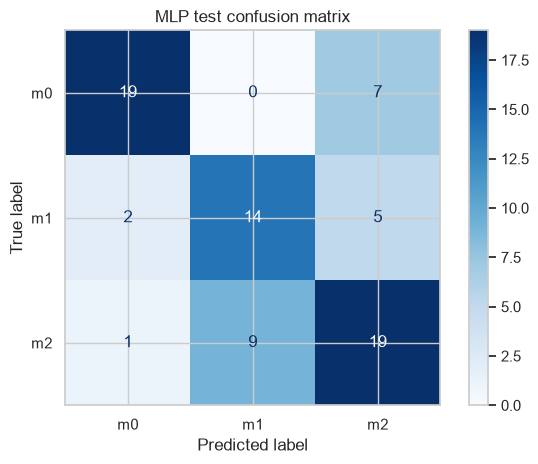

Best model test balanced accuracy: 0.684202770409667
Best model test macro F1: 0.6871212121212121


In [44]:
print(classification_report(
    y_test,
    pred_xgb,
    target_names=class_names,
    digits=3,
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_xgb,
    display_labels=class_names,
    cmap="Blues",
)
plt.title("MLP test confusion matrix")
plt.tight_layout()
plt.show()

print("Best model test balanced accuracy:", balanced_accuracy_score(y_test, pred_xgb))
print("Best model test macro F1:", f1_score(y_test, pred_xgb, average="macro"))


## Answers for "questions for the report" part:
1. Did the embedding space show visible separation between the cell types? 

Kind of, they are not clearly separated but seem to dominate different areas on the plots.

2. Which learning rate and architecture performed best, and what evidence supports that choice?

lr 1e-3, with deep architecture (corresponfing to lhidden layers dimensions (64, 32, 16)). As the evidence I took validation accuracy, this model achieved the highest.

3. Did the MLP overfit? Use the training and validation curves to justify your answer.

Yes, some of the experiments overfit (mentioned in the notebook when), this is seen when training loss continues decreasing, while validation loss starts to increase.

4. Which regularization method was most useful?

In this case, early stopping was the most useful, as it is straight-forward compared to dropout, and performed on the same level. Also it saved few seconds on the corresponding training run.

5. How did the MLP compare with logistic regression and XGBoost?

In this case MLP was performing warse than logistic regression and XGBoost.

6. Which cell types were most frequently confused?

m2 is most frequently confused with other cell types and the m2 label (when the model predicts m2) also is the least reliable. This can be observed from the confusion matrix. On Umap we can see that m2 class occupies midle segment of plot, between m1 and m0, therefore it is reasonable that model confuses it the most.

7. What additional biological or technical information would help explain the errors?

What are the classes corresponding to (if there is actually progression m1->m2->m0 or ist it accidental). Also if there were any different technical protocols used for the samples which model confused.



Here is the table of all trained models (MLP mentioned only ones (best), as it is anyway logged to MLFlow):

| Model | Balanced accuracy (vaal) | Macro F1 (val) | Notes |
|---|---:|---:|---|
| Logistic Regression | 0.636 | 0.626| linear baseline |
| XGBoost | 0.665 | 0.652 | tuned tree-boosting model |
| MLP (best)| 0.634 | 0.616 | neural-network model |

Limitations:
- I used only subset of features to speed up the workflow, maybe using all of them or removing less aggressively would bring better results
- Even though we did group-aware split, some groups may still be closer to each-other than others (ex: different microscopy techniques) and maybe additional exploration or understanfing of this column would be beneficial.